# 3. Mixed variables, constraints and choosing a design

Building choices are often **categorical** (a glazing type) or **integer** (a number of shading levels), and
often **constrained** (a budget). This tutorial shows how bdopt handles them, with a Python function standing in
for the simulator so it runs in seconds. Everything shown works the same with an
{class}`~bdopt.EnergyPlusEvaluator`.

The toy problem: choose a wall insulation thickness, a glazing type and a number of shading levels to minimise
heat loss and cost and maximise daylight, with a cost cap.

In [1]:
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

## Parameters of three kinds

In [2]:
from bdopt import (CategoryParameter, FunctionEvaluator, GenericSelector, IntegerParameter, Objective,
                   Parameter, Problem, RangeParameter)

noop = GenericSelector(lambda idf, value: None)        # no model file in this tutorial

parameters = [
    Parameter(noop, RangeParameter(0.05, 0.40), name="insulation [m]"),
    Parameter(noop, CategoryParameter(["single", "double", "triple"]), name="glazing"),
    Parameter(noop, IntegerParameter(0, 4), name="shading levels"),
]

# glazing: (U-value, daylight transmittance, cost per m2)
GLAZING = {"single": (5.7, 0.90, 40.0), "double": (2.8, 0.78, 90.0), "triple": (1.2, 0.68, 160.0)}

def simulator(row):
    u, daylight, glazing_cost = GLAZING[row["glazing"]]
    heat_loss = 100 / (1 + 12 * row["insulation [m]"]) + 9 * u - 1.5 * row["shading levels"]
    cost = 400 * row["insulation [m]"] + glazing_cost + 6 * row["shading levels"]
    daylight_score = 100 * daylight * (1 - 0.12 * row["shading levels"])
    return [heat_loss, cost, daylight_score]

objectives = [
    "heat loss",
    "cost",
    Objective("daylight", direction="max"),            # an objective to maximise
]
problem = Problem(
    parameters, objectives,
    constraints=[lambda row: GLAZING[row["glazing"]][2] + 400 * row["insulation [m]"] - 190.0],   # cost cap
)
evaluator = FunctionEvaluator(problem, simulator)
problem.names()

['insulation [m]',
 'glazing',
 'shading levels',
 'heat loss',
 'cost',
 'daylight']

A plain string is an objective to minimise (with an EnergyPlus evaluator it would be a meter name);
`Objective("daylight", direction="max")` names an objective to **maximise**. The constraint is a function of a
design that returns a number, feasible when it is `<= 0`.

## Sampling respects discrete values and constraints

In [3]:
from bdopt import sampling

designs = sampling.lhs(problem, 200, seed=0)
print(designs["glazing"].value_counts().to_dict(), sorted(designs["shading levels"].unique()))
print("all feasible:", bool(problem.feasible(designs).all()))
designs.head()

{'single': 119, 'double': 73, 'triple': 8} [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
all feasible: True


,insulation [m],glazing,shading levels
0,0.3009,single,4
1,0.0523,triple,4
2,0.3251,single,2
3,0.1784,double,1
4,0.0724,single,3


## A surrogate over mixed variables

Categories and integers are encoded in the unit cube, so the same surrogate classes work unchanged.

In [4]:
from bdopt.surrogate import GPSurrogate

train = evaluator.evaluate(sampling.lhs(problem, 80, seed=1), keep_input=True)
test = evaluator.evaluate(sampling.lhs(problem, 200, seed=2), keep_input=True)
surrogate = GPSurrogate().fit(train, problem)
surrogate.score(test).round(3)

,rmse,rmse_pct,nrmse,cv_rmse,nmbe,mae,r2
heat loss,0.006,0.009,0.0,0.009,-0.0,0.002,1.0
cost,0.007,0.005,0.0,0.005,-0.0,0.001,1.0
daylight,0.000,0.001,0.0,0.001,0.0,0.000,1.0


## NSGA-II on the surrogate

Discrete coordinates are snapped to valid values during the search, so every design on the front has a real
glazing type and an integer number of shading levels, and the front respects the cost cap.

In [5]:
from bdopt.optimize import nsga2

front = nsga2(problem, surrogate, pop_size=120, n_gen=80, seed=0)
print(len(front), "designs;", "glazings:", sorted(front.df["glazing"].unique()),
      "| shading levels:", sorted(front.df["shading levels"].unique()))
print("cost cap respected:", bool(problem.feasible(front.parameters).all()))
front.df.sort_values("cost").head(8)

120 designs; glazings: ['double', 'single'] | shading levels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
cost cap respected: True


,insulation [m],glazing,shading levels,heat loss,cost,daylight
3,0.0500,single,0,113.7428,60.0014,89.9999
7,0.0500,single,0,113.7428,60.0014,89.9999
109,0.0505,single,0,113.5383,60.1822,89.9999
36,0.0534,single,0,112.2382,61.3526,89.9999
26,0.0570,single,0,110.6763,62.8115,89.9999
95,0.0603,single,0,109.3359,64.1151,89.9999
77,0.0637,single,0,107.9742,65.4951,89.9999
29,0.0670,single,0,106.7485,66.7915,89.9999


## Choosing one design

{meth}`~bdopt.optimize.ParetoFront.closest_to_ideal` picks the design nearest to the ideal point, after scaling
each objective to $[0, 1]$ over the front. `weights` say which objective matters more.

In [6]:
equal = front.closest_to_ideal()
daylight_first = front.closest_to_ideal(weights=[1, 1, 3])
pd.DataFrame({"equal weights": equal, "daylight x3": daylight_first})

,equal weights,daylight x3
insulation [m],0.1068,0.1851
glazing,double,single
shading levels,0,0
heat loss,69.0316,82.3411
cost,132.7212,114.051
daylight,78.0,90.0


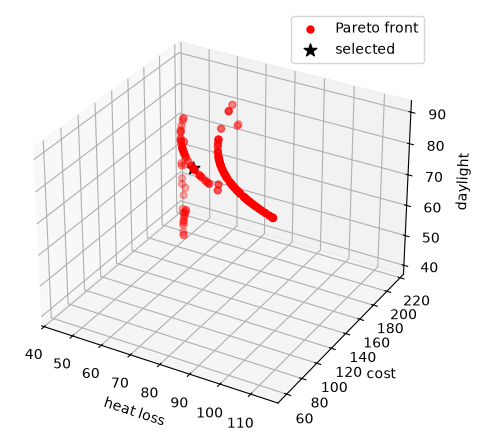

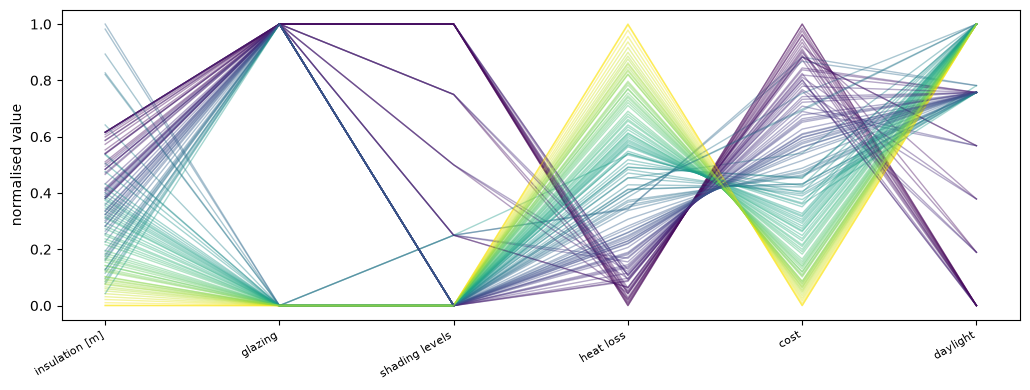

In [7]:
from bdopt import viz

viz.pareto(front, highlight=equal)
plt.show()
viz.parallel_coordinates(front.df, problem)
plt.show()

## Check against the "simulator"

The front holds the surrogate's predictions; evaluate the same designs with the simulator to see the
surrogate's error on the designs that matter.

In [8]:
actual = evaluator.evaluate(front.parameters)
error = (front.objectives.to_numpy() - actual.to_numpy()) / actual.to_numpy().std(axis=0)
pd.Series(np.sqrt((error ** 2).mean(axis=0)), index=problem.objective_names, name="RMSE / std")

heat loss    4.4781e-04
cost         6.3001e-06
daylight     2.7373e-06
Name: RMSE / std, dtype: float64

## Next

* Real model: {doc}`02_office_building`.
* Whole pipeline from a file: {doc}`../guide/studies`.